# D06 · A fast kernel is not a fast service
Compare native and ONNX execution at two batch sizes, separate warm/request/startup timings, and calculate an illustrative end-to-end speedup limit.
**Prerequisites:** basic Python and the [learning guide](../docs/LEARNING_GUIDE.md).
**Evidence boundary:** the charts read the recorded October 26, 2026 experiments by default. Running this notebook recomputes plots and teaching calculations; it does not retrain a model or run new model inference. Illustrative examples below are labeled separately. The [notebook guide](README.md) explains setup, provenance, and how to export your own completed runs.

## Load the evidence
Run all cells in order. The loader prints the run IDs, dates, seeds and scope. A custom export does not automatically rewrite the historical interpretation in this lesson.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/lab.py").is_file() and (p / "src/ml_training").is_dir())
for folder in [ROOT / "notebooks", ROOT / "src"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from lab import load_demo, style, grouped_bars
style()

# None uses the compact checked-in snapshot. To inspect a new export, set an
# explicit path, e.g. ROOT / "artifacts/my-notebook-results.json". Missing files fail.
SNAPSHOT_PATH = None
d = load_demo("D06", SNAPSHOT_PATH)

Matplotlib is building the font cache; this may take a moment.


D06 | recorded experiment data | recorded_results.json
Recorded local educational experiments. Inspect run dates, seeds and source manifests before comparing results. No production or physical-device validation.
Run: artifacts/fast_classifier/local-s41-20261026T163410Z-e369ea | recorded: 20261026T163410Z | seed: 41
Run: artifacts/fast_classifier/local-s42-20261026T163413Z-7840a0 | recorded: 20261026T163413Z | seed: 42
Run: artifacts/fast_classifier/local-s43-20261026T163417Z-e84941 | recorded: 20261026T163417Z | seed: 43


## The concept
Export parity checks whether native and converted predictions agree within a stated tolerance. It does not test the target label. Timing answers another question: which portion of the request is expensive?
Batch latency, per-row throughput, HTTP response time and process startup have different scopes. Do not add their p95 values or subtract percentiles to infer component time; percentile arithmetic does not compose that way.

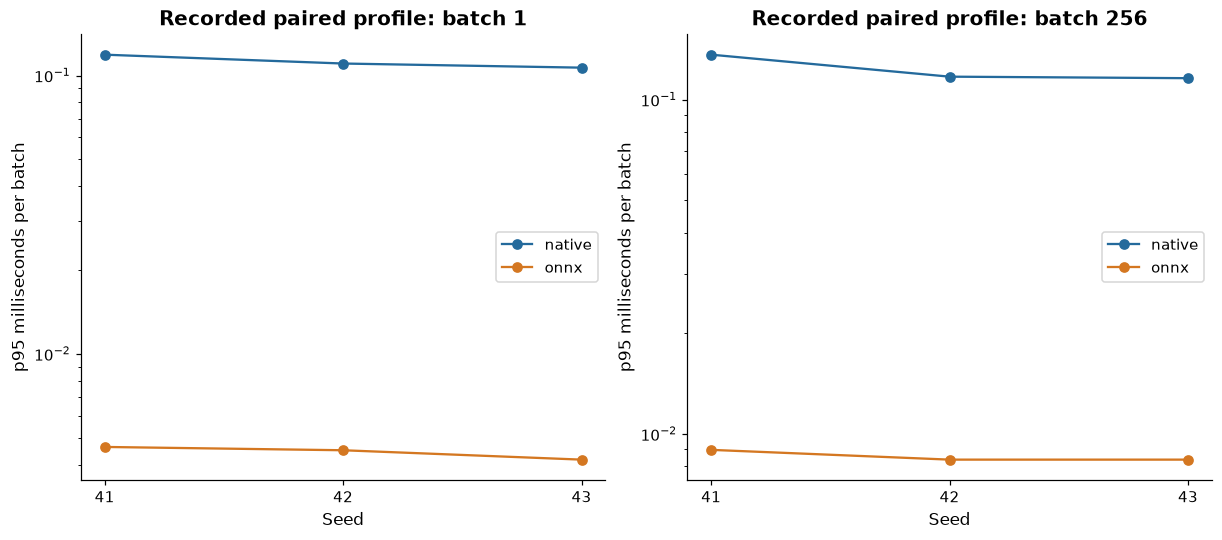

Largest paired-batch parity error: 8.940696716308594e-08


In [2]:
paired = d['paired_profiles']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout='constrained')
for ax, batch in zip(axes, ['1', '256']):
    for backend in ['native', 'onnx']:
        ax.plot([r['seed'] for r in paired],
                [r['batch_profiles'][batch]['backends'][backend]['p95'] for r in paired],
                'o-', label=backend)
    ax.set(yscale='log', xlabel='Seed', ylabel='p95 milliseconds per batch', title=f'Recorded paired profile: batch {batch}')
    ax.set_xticks([r['seed'] for r in paired]); ax.legend()
plt.show()
print('Largest paired-batch parity error:', max(p['parity_max_abs_error'] for r in paired for p in r['batch_profiles'].values()))

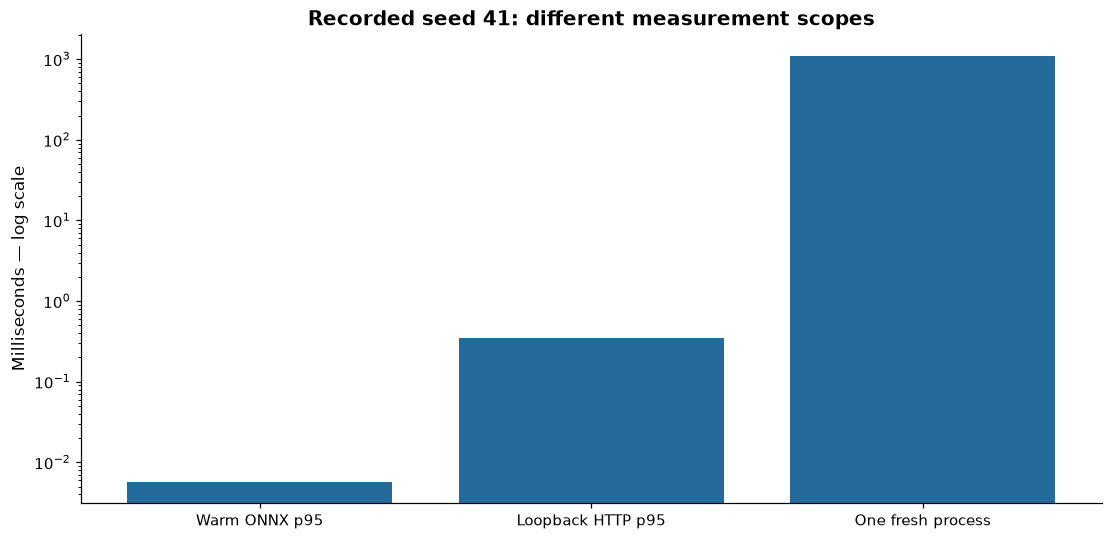

In [3]:
r = next(r for r in d['runs'] if r['seed'] == 41)
b = r['benchmarks']
names = ['Warm ONNX p95', 'Loopback HTTP p95', 'One fresh process']
milliseconds = [b['onnx_batch_1']['p95'], b['http_batch_1']['p95'],
                b['fresh_process_first_inference']['process_start_to_exit_seconds'] * 1000]
fig, ax = plt.subplots(layout='constrained')
ax.bar(names, milliseconds); ax.set_yscale('log')
ax.set(ylabel='Milliseconds — log scale', title='Recorded seed 41: different measurement scopes')
plt.show()

### Change the fraction that can be accelerated
**Amdahl's law illustration:** if model execution occupies fraction `f` of serial request time and becomes `s` times faster, overall speedup is `1 / ((1 − f) + f/s)`. This is a simplified arithmetic model. Queueing, batch delay and parallel execution are outside it; `f` below was not measured by subtracting percentiles.

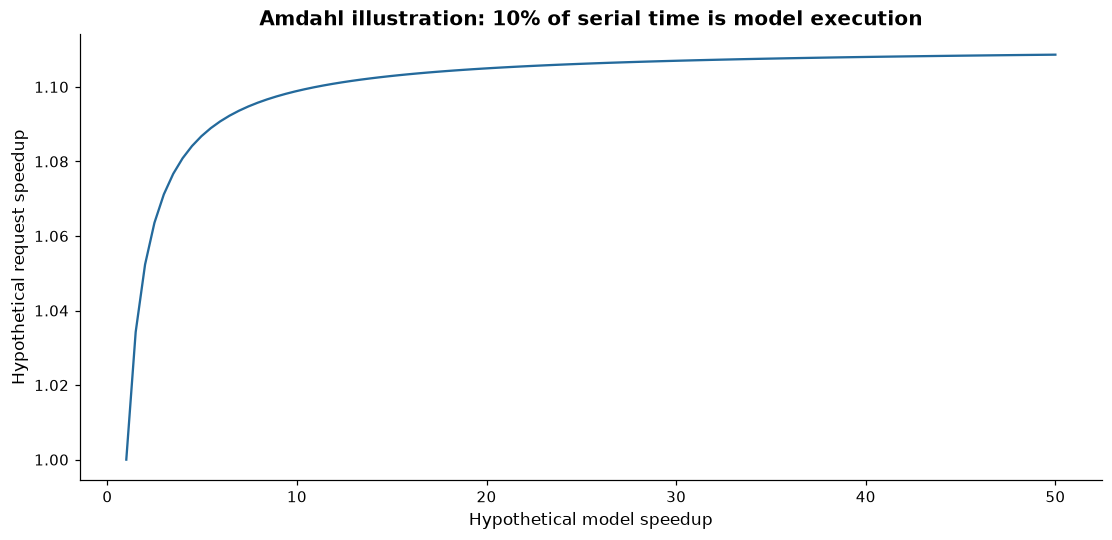

In [4]:
model_fraction = 0.10  # Hypothesis from profiling; try .5 or .9.
kernel_speedup = np.linspace(1, 50, 100)
overall = 1 / ((1 - model_fraction) + model_fraction / kernel_speedup)
fig, ax = plt.subplots(layout='constrained')
ax.plot(kernel_speedup, overall)
ax.set(xlabel='Hypothetical model speedup', ylabel='Hypothetical request speedup',
       title=f'Amdahl illustration: {model_fraction:.0%} of serial time is model execution')
plt.show()

**Interpretation check:** the large batch-256 rows/s values describe repeated inputs in a tight process loop. They are not HTTP throughput. The fresh-process number is one observation including imports/loading, with uncontrolled filesystem caches. Neither establishes production p95 under load.

## What you learned and when to use it
Optimize after profiling. Exported runtimes, resident models, batching and compilation are alternatives with maintenance costs. Preserve feature ordering and numerical parity, then measure the entire request at representative concurrency.
**Architecture exercise:** state a quality floor, a simpler alternative, and the evidence that would make you reject this approach. Compare your answer with the [decision guide](../docs/ARCHITECTURE_DECISION_GUIDE.md#d06--optimize-inference-execution).
**Train or run the actual model:** follow the [D06 tutorial](../docs/CPU_DEMOS.md#d06-export-and-time-a-request-classifier). Training stays in its existing locked environment; this notebook stays light enough to run without model downloads.
[All visual lessons](README.md) · [Production tradeoffs](../docs/PRODUCTION_TRADEOFFS.md)